<a href="https://colab.research.google.com/github/devangc006/Ai-ML/blob/main/RDM_FRST_SVC_ENSMB_MTD_ID3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

             ACCURACY AND CLASSIFICATION REPORTS                  

--- MODEL: ID3 DECISION TREE ---
Overall Accuracy: 94.74%

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.90      0.93        42
      benign       0.95      0.97      0.96        72

    accuracy                           0.95       114
   macro avg       0.95      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114

------------------------------------------------------------------

--- MODEL: SUPPORT VECTOR MACHINE (SVC) ---
Overall Accuracy: 98.25%

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

-----------------------------------

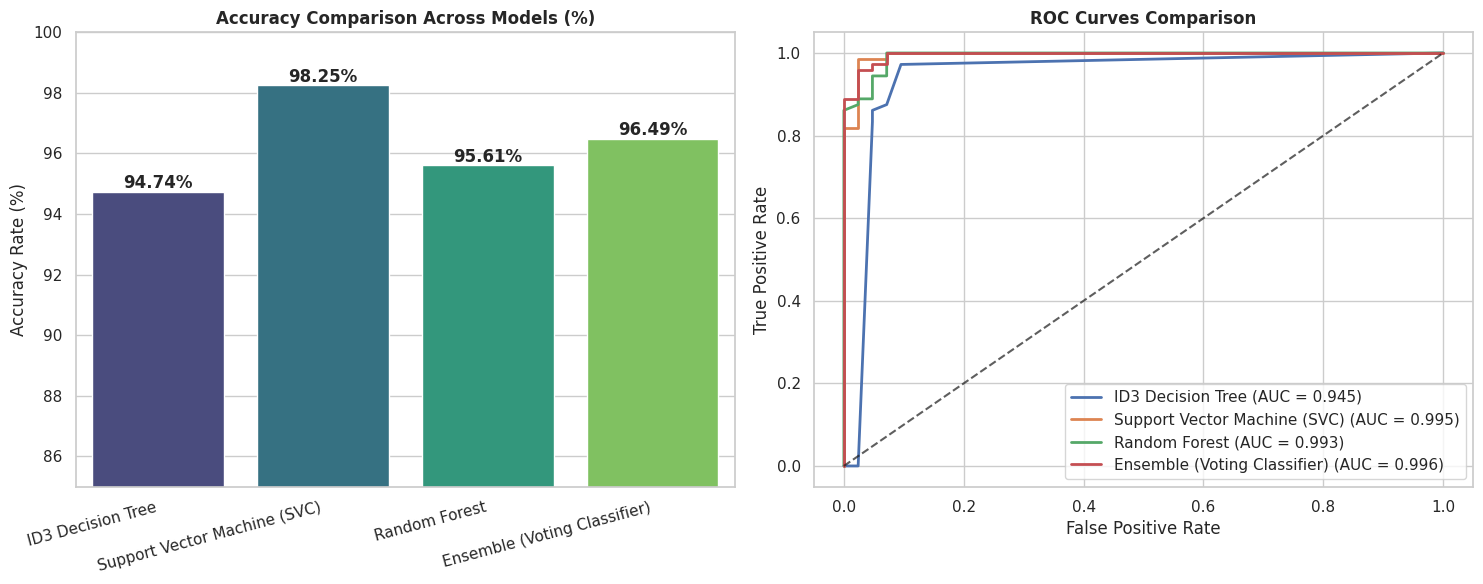

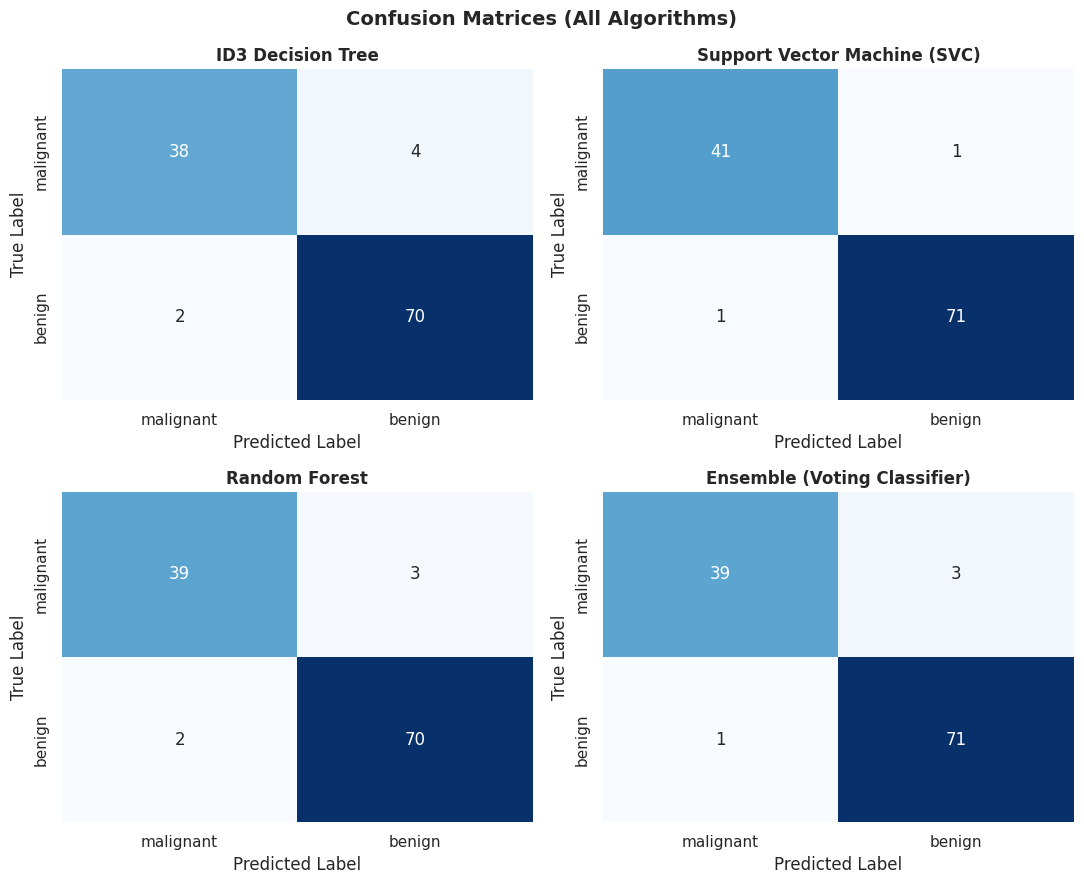

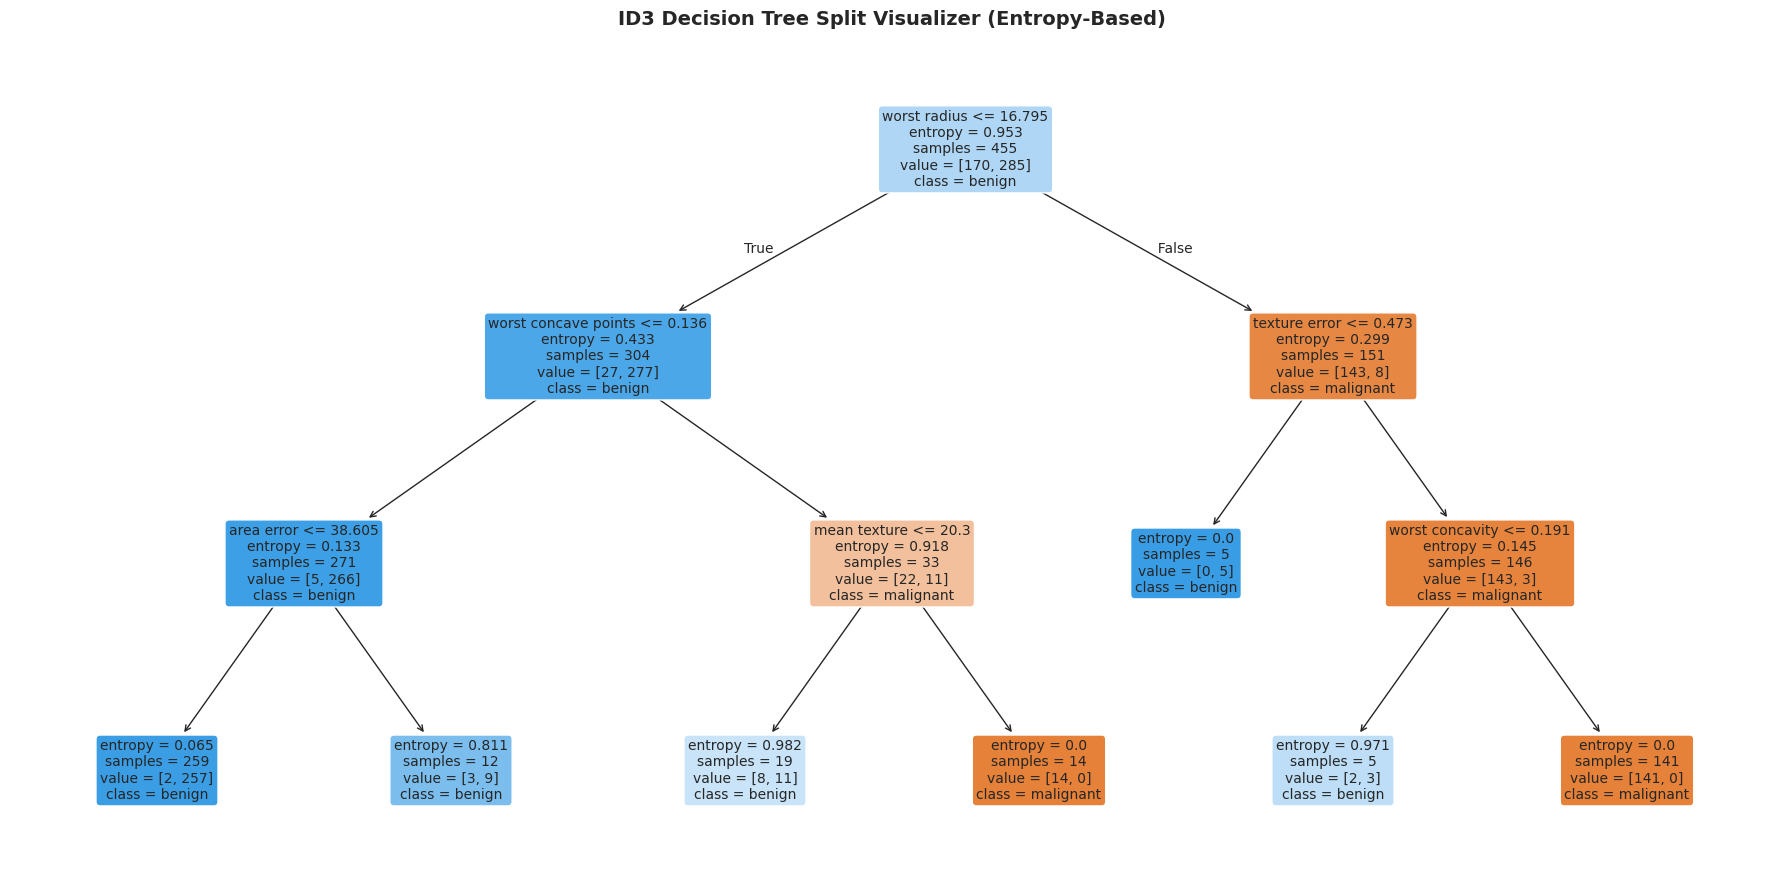

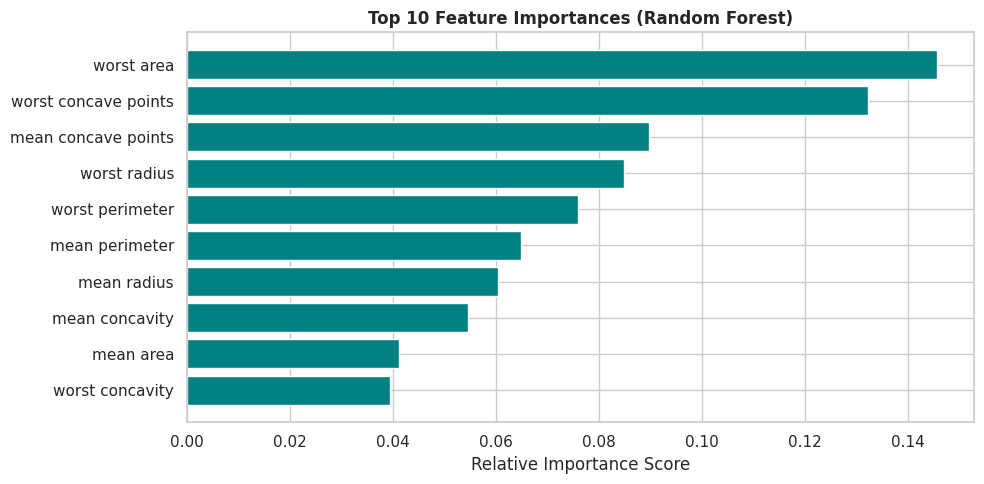

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

# -------------------------------------------------------------------
# 1. Dataset Loading & Preparation
# -------------------------------------------------------------------
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

# Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Feature Scaling (Essential for SVC)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# -------------------------------------------------------------------
# 2. Model Initialization
# -------------------------------------------------------------------
# Note: criterion='entropy' and max_depth=3 implement ID3 Information Gain logic
id3_model = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
svc_model = SVC(kernel='rbf', C=1.0, probability=True, random_state=42)
rf_model = RandomForestClassifier(n_estimators=100, criterion='entropy', random_state=42)

ensemble_model = VotingClassifier(
    estimators=[
        ('id3', id3_model),
        ('svc', svc_model),
        ('rf', rf_model)
    ],
    voting='soft'
)

models = {
    'ID3 Decision Tree': id3_model,
    'Support Vector Machine (SVC)': svc_model,
    'Random Forest': rf_model,
    'Ensemble (Voting Classifier)': ensemble_model
}

# -------------------------------------------------------------------
# 3. Model Training, Prediction & Evaluation Metrics
# -------------------------------------------------------------------
preds = {}
probs = {}
accuracies = {}

print("==================================================================")
print("             ACCURACY AND CLASSIFICATION REPORTS                  ")
print("==================================================================\n")

for name, model in models.items():
    # Fit & predict based on whether scaling is needed
    if name in ['Support Vector Machine (SVC)', 'Ensemble (Voting Classifier)']:
        model.fit(X_train_scaled, y_train)
        preds[name] = model.predict(X_test_scaled)
        probs[name] = model.predict_proba(X_test_scaled)[:, 1]
    else:
        model.fit(X_train, y_train)
        preds[name] = model.predict(X_test)
        probs[name] = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, preds[name])
    accuracies[name] = acc

    # Print Accuracy and Full Classification Report for EACH algorithm
    print(f"--- MODEL: {name.upper()} ---")
    print(f"Overall Accuracy: {acc * 100:.2f}%\n")
    print("Classification Report:")
    print(classification_report(y_test, preds[name], target_names=data.target_names))
    print("-" * 66 + "\n")


# -------------------------------------------------------------------
# 4. Plot 1: Model Accuracy Bar Chart & ROC Curves
# -------------------------------------------------------------------
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Accuracy Comparison Bar Chart
palette = sns.color_palette("viridis", len(models))
bars = sns.barplot(
    x=list(accuracies.keys()),
    y=[v * 100 for v in accuracies.values()],
    hue=list(accuracies.keys()), # Fixed: Assign x to hue
    palette=palette,
    legend=False, # Fixed: Set legend to False
    ax=axes[0]
)
axes[0].set_title("Accuracy Comparison Across Models (%)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Accuracy Rate (%)")
axes[0].set_ylim(85, 100)
# Fixed: Set x-ticks explicitly before setting labels
axes[0].set_xticks(range(len(accuracies.keys())))
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=15, ha='right')

for bar in bars.patches:
    axes[0].annotate(
        f"{bar.get_height():.2f}%",
        (bar.get_x() + bar.get_width() / 2.0, bar.get_height()),
        ha="center", va="center", xytext=(0, 6), textcoords="offset points", fontweight="bold"
    )

# ROC Curves Comparison Plot
for name in models.keys():
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    roc_auc = auc(fpr, tpr)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})", linewidth=2)

axes[1].plot([0, 1], [0, 1], "k--", alpha=0.7)
axes[1].set_title("ROC Curves Comparison", fontsize=12, fontweight="bold")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend(loc="lower right")

plt.tight_layout()

# -------------------------------------------------------------------
# 5. Plot 2: Confusion Matrices Grid for All Algorithms
# -------------------------------------------------------------------
fig_cm, axes_cm = plt.subplots(2, 2, figsize=(11, 9))
fig_cm.suptitle("Confusion Matrices (All Algorithms)", fontsize=14, fontweight="bold")

for idx, (name, pred) in enumerate(preds.items()):
    ax = axes_cm[idx // 2, idx % 2]
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=data.target_names, yticklabels=data.target_names
    )
    ax.set_title(name, fontweight="bold")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

plt.tight_layout()

# -------------------------------------------------------------------
# 6. Plot 3: Dedicated ID3 Decision Tree Visualization
# -------------------------------------------------------------------
plt.figure(figsize=(18, 9))
plot_tree(
    id3_model,
    feature_names=data.feature_names,
    class_names=data.target_names,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("ID3 Decision Tree Split Visualizer (Entropy-Based)", fontsize=14, fontweight="bold", pad=15)
plt.tight_layout()

# -------------------------------------------------------------------
# 7. Plot 4: Random Forest Feature Importances
# -------------------------------------------------------------------
plt.figure(figsize=(10, 5))
importances = rf_model.feature_importances_
indices = np.argsort(importances)[-10:]
plt.barh(range(10), importances[indices], color="teal")
plt.yticks(range(10), [data.feature_names[i] for i in indices])
plt.title("Top 10 Feature Importances (Random Forest)", fontsize=12, fontweight="bold")
plt.xlabel("Relative Importance Score")
plt.tight_layout()

plt.show()